In [ ]:
###### MedMNIST Project - HEND Tarek

In [4]:
%pip install medmnist

Note: you may need to restart the kernel to use updated packages.


In [1]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.


#### 1. Data visualisation

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import torchvision.models as models

import medmnist
from medmnist import PathMNIST
from sklearn.metrics import classification_report, confusion_matrix

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Utilisation du matériel : {device}")

Utilisation du matériel : cpu


### Etape 2 : Chargement et prétraitement des données

In [2]:
data_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])


train_dataset = PathMNIST(split='train', transform=data_transform, download=True)
val_dataset   = PathMNIST(split='val', transform=data_transform, download=True)
test_dataset  = PathMNIST(split='test', transform=data_transform, download=True)


BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)


labels_map = train_dataset.info['label']
num_classes = len(labels_map)
print(f"Nombre de classes : {num_classes}")
print("Dictionnaire des classes :", labels_map)

Nombre de classes : 9
Dictionnaire des classes : {'0': 'adipose', '1': 'background', '2': 'debris', '3': 'lymphocytes', '4': 'mucus', '5': 'smooth muscle', '6': 'normal colon mucosa', '7': 'cancer-associated stroma', '8': 'colorectal adenocarcinoma epithelium'}


### Etape 3 : exploration et visualisation des données

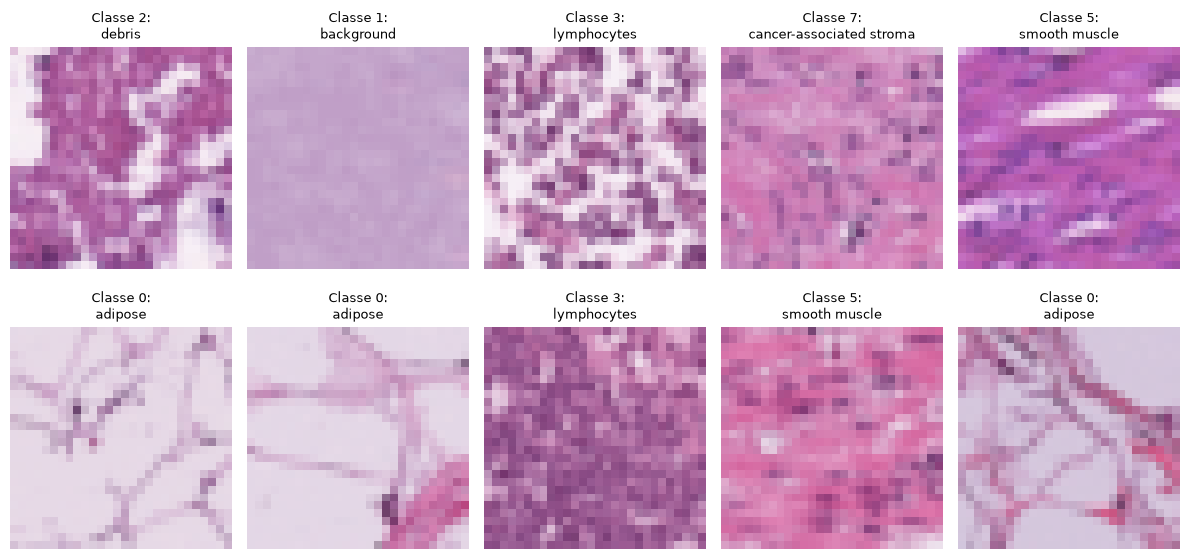

In [3]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for idx, ax in enumerate(axes.flat):
    img = images[idx].permute(1, 2, 0).numpy() * 0.5 + 0.5
    lbl = labels[idx].item()
    
    ax.imshow(img)
    ax.set_title(f"Classe {lbl}:\n{labels_map[str(lbl)]}", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()

### Etape 4 : implémentation du CNN

In [4]:
class PathMNISTNet(nn.Module):
    def __init__(self, num_classes=9):
        super(PathMNISTNet, self).__init__()
        
        self.features = nn.Sequential(
            
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 14x14
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 7x7
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU()
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = PathMNISTNet(num_classes=num_classes).to(device)
print(model)

PathMNISTNet(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6272, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_featur

### Etape 5 : entraînement et validation

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, targets in loader:
        inputs = inputs.to(device)
        targets = targets.squeeze().long().to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()
        
    return running_loss / total, correct / total

def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)
            targets = targets.squeeze().long().to(device)
            
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            
            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()
            
    return running_loss / total, correct / total

# Boucle principale d'entraînement
EPOCHS = 10
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)
    
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    
    print(f"Époque [{epoch+1}/{EPOCHS}] | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc*100:.2f}%")

Époque [1/10] | Train Loss: 0.5793 Acc: 79.24% | Val Loss: 0.6515 Acc: 78.54%
Époque [2/10] | Train Loss: 0.3479 Acc: 87.94% | Val Loss: 0.7815 Acc: 74.21%
Époque [3/10] | Train Loss: 0.2645 Acc: 90.81% | Val Loss: 0.2965 Acc: 89.69%
Époque [4/10] | Train Loss: 0.2139 Acc: 92.61% | Val Loss: 0.3652 Acc: 87.89%
Époque [5/10] | Train Loss: 0.1887 Acc: 93.54% | Val Loss: 1.0739 Acc: 76.34%
Époque [6/10] | Train Loss: 0.1824 Acc: 93.78% | Val Loss: 0.2092 Acc: 92.49%
Époque [7/10] | Train Loss: 0.1475 Acc: 95.00% | Val Loss: 0.2146 Acc: 93.24%
Époque [8/10] | Train Loss: 0.1350 Acc: 95.42% | Val Loss: 0.2536 Acc: 92.08%
Époque [9/10] | Train Loss: 0.1260 Acc: 95.77% | Val Loss: 0.1645 Acc: 94.45%
Époque [10/10] | Train Loss: 0.1112 Acc: 96.13% | Val Loss: 0.2920 Acc: 90.82%


### Etape 6 : évaluation et confusion matrix

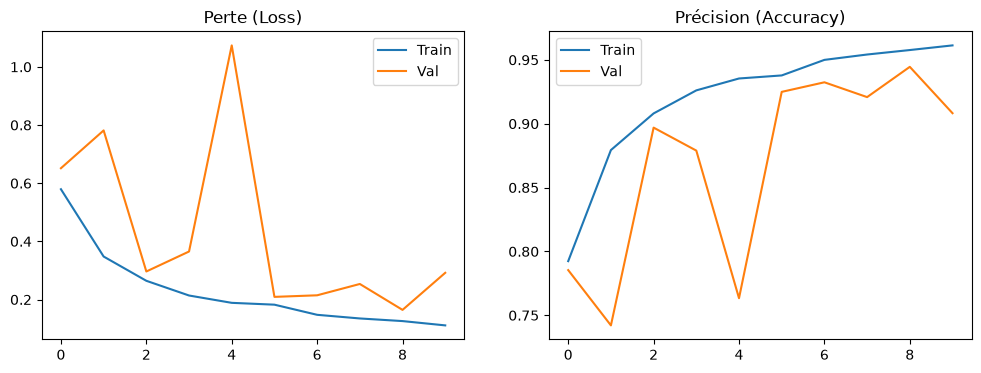

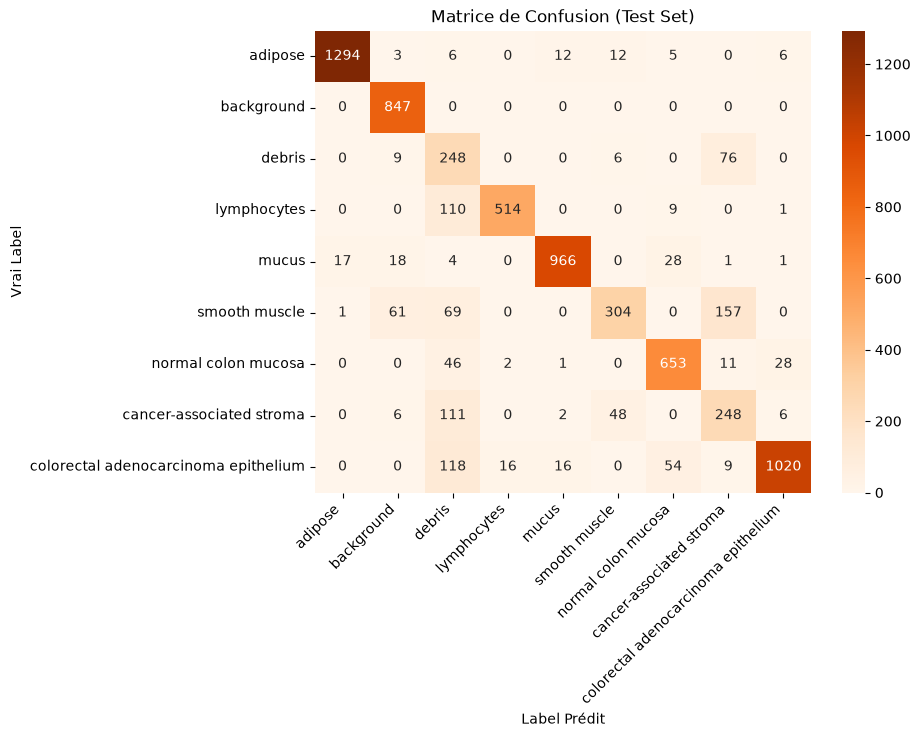


Rapport de classification :
                                      precision    recall  f1-score   support

                             adipose       0.99      0.97      0.98      1338
                          background       0.90      1.00      0.95       847
                              debris       0.35      0.73      0.47       339
                         lymphocytes       0.97      0.81      0.88       634
                               mucus       0.97      0.93      0.95      1035
                       smooth muscle       0.82      0.51      0.63       592
                 normal colon mucosa       0.87      0.88      0.88       741
            cancer-associated stroma       0.49      0.59      0.54       421
colorectal adenocarcinoma epithelium       0.96      0.83      0.89      1233

                            accuracy                           0.85      7180
                           macro avg       0.81      0.81      0.80      7180
                        weighted 

In [9]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history['train_loss'], label='Train')
ax1.plot(history['val_loss'], label='Val')
ax1.set_title('Perte (Loss)')
ax1.legend()

ax2.plot(history['train_acc'], label='Train')
ax2.plot(history['val_acc'], label='Val')
ax2.set_title('Précision (Accuracy)')
ax2.legend()
plt.show()


model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_targets.extend(targets.squeeze().numpy())


cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=labels_map.values(),
            yticklabels=labels_map.values())
plt.ylabel('Vrai Label')
plt.xlabel('Label Prédit')
plt.title('Matrice de Confusion (Test Set)')
plt.xticks(rotation=45, ha='right')
plt.show()

# Rapport de classification
print("\nRapport de classification :")
print(classification_report(all_targets, all_preds, target_names=list(labels_map.values())))

### Visualisation des résultats


D'après nos résultats, nous avons une accuracy globale de 85% sur le jeu de test. La courbe Train est correcte et monte jusqu'à environ 95-96%. Le modèle apprend bien ce qu'on lui montre, mais la courbe Val est beaucoup plus agitée et présente des pics d'erreur. Je peux constater que vers les époques 7 à 9, il y a un début d'overfitting : la perte d'entraînement descend doucement alors que la validation remonte un peu, et l'accuracy décroche directement.

- adipose (tissu adipeux) et background (fond) ont de très bons scores (0.98 et 0.95), ils sont facilement distingués ici par notre modèle.
- debris a un score F1 de 0.47, donc le modèle les confond souvent avec d'autres éléments. En regardant la confusion matrix, sur 339 débris réels, 76 ont été prédits comme de l'épithélium.
- cancer-associated stroma a un score de 0.54, même problème, souvent confondu avec le stroma normal ou les debris.
- smooth muscle a un F1 Score de 0.63 et un mauvais recall de 0.51, signifiant que le modèle rate la moitié des vrais muscles lisses.


### Etape 5 : amélioration du système

- Solution envisagée : data augmentation (générer artificiellement de nouvelles images d'entraînement à partir des images existantes, pour y appliquer des transformations aléatoires (rotations légères, retournements, modifications de luminosité...).

- Le but est de lutter contre l'overfitting, comme on a pu le voir sur les courbes précédentes. Cela permet aussi de facilement augmenter le dataset et améliorer la robustesse. Nous ajouterons aussi une L2-Regularisation. Une validation croisée serait possible mais prendrait beaucoup trop de temps de calcul sur ce dataset, surtout si le travail est effectué avec un simple CPU sur Mac.

Utilisation du matériel : cpu
Nombre de classes : 9
Début de l'entraînement...
Époque [1/10] | Train Loss: 0.7262 Acc: 73.45% | Val Loss: 0.5172 Acc: 80.89%
Époque [2/10] | Train Loss: 0.4781 Acc: 83.06% | Val Loss: 0.4428 Acc: 84.61%
Époque [3/10] | Train Loss: 0.3897 Acc: 86.46% | Val Loss: 0.4517 Acc: 83.97%
Époque [4/10] | Train Loss: 0.3450 Acc: 88.11% | Val Loss: 0.4583 Acc: 85.58%
Époque [5/10] | Train Loss: 0.3020 Acc: 89.72% | Val Loss: 0.3616 Acc: 87.37%
Époque [6/10] | Train Loss: 0.2768 Acc: 90.63% | Val Loss: 0.3398 Acc: 89.07%
Époque [7/10] | Train Loss: 0.2578 Acc: 91.28% | Val Loss: 0.2471 Acc: 91.32%
Époque [8/10] | Train Loss: 0.2395 Acc: 91.97% | Val Loss: 0.8524 Acc: 79.83%
Époque [9/10] | Train Loss: 0.2279 Acc: 92.41% | Val Loss: 0.5219 Acc: 82.88%
Époque [10/10] | Train Loss: 0.2164 Acc: 92.82% | Val Loss: 0.2350 Acc: 92.86%


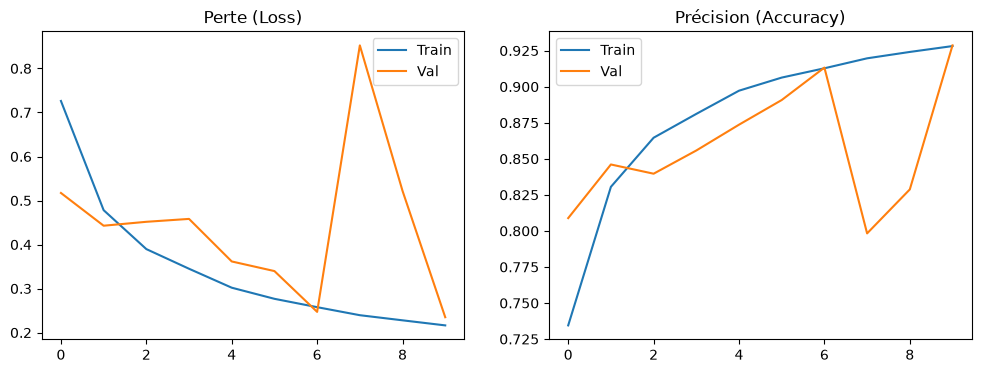

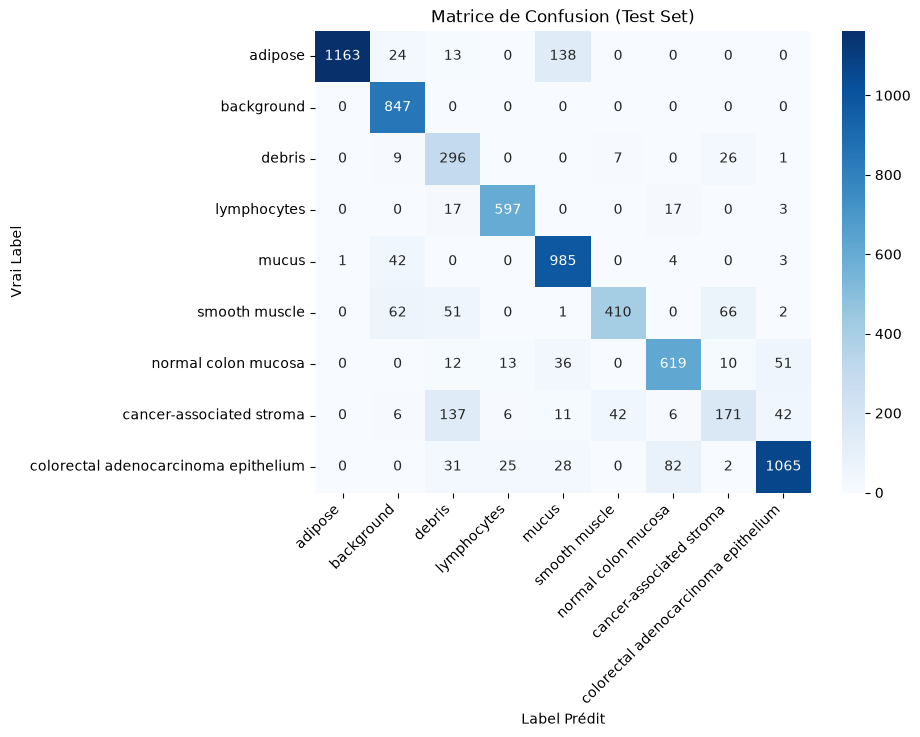


Rapport de classification :
                                      precision    recall  f1-score   support

                             adipose       1.00      0.87      0.93      1338
                          background       0.86      1.00      0.92       847
                              debris       0.53      0.87      0.66       339
                         lymphocytes       0.93      0.94      0.94       634
                               mucus       0.82      0.95      0.88      1035
                       smooth muscle       0.89      0.69      0.78       592
                 normal colon mucosa       0.85      0.84      0.84       741
            cancer-associated stroma       0.62      0.41      0.49       421
colorectal adenocarcinoma epithelium       0.91      0.86      0.89      1233

                            accuracy                           0.86      7180
                           macro avg       0.82      0.83      0.81      7180
                        weighted 

In [11]:
# ==========================================
# ÉTAPE 1 : IMPORTATIONS ET CONFIGURATION
# ==========================================
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision.transforms as transforms

import medmnist
from medmnist import PathMNIST
from sklearn.metrics import classification_report, confusion_matrix

# Fixer le seed pour la reproductibilité
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

# Choix du matériel (GPU si disponible)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Utilisation du matériel : {device}")


# ==========================================
# ÉTAPE 2 : DONNÉES ET DATA AUGMENTATION
# ==========================================
# Transformations avec Data Augmentation pour l'entraînement
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# Transformations standards pour la validation et le test (pas d'aléa)
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# Chargement des datasets
train_dataset = PathMNIST(split='train', transform=train_transform, download=True)
val_dataset   = PathMNIST(split='val', transform=eval_transform, download=True)
test_dataset  = PathMNIST(split='test', transform=eval_transform, download=True)

# DataLoaders
BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

labels_map = train_dataset.info['label']
num_classes = len(labels_map)
print(f"Nombre de classes : {num_classes}")


# ==========================================
# ÉTAPE 3 : ARCHITECTURE DU MODÈLE (CNN)
# ==========================================
class PathMNISTNet(nn.Module):
    def __init__(self, num_classes=9):
        super(PathMNISTNet, self).__init__()
        
        self.features = nn.Sequential(
            # Bloc 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 14x14
            
            # Bloc 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 7x7
            
            # Bloc 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU()
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.5), # Dropout augmenté à 0.5 pour plus de régularisation
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = PathMNISTNet(num_classes=num_classes).to(device)


# ==========================================
# ÉTAPE 4 : ENTRAÎNEMENT ET VALIDATION
# ==========================================
criterion = nn.CrossEntropyLoss()
# Ajout du weight_decay=1e-4 pour la régularisation L2
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, targets in loader:
        inputs = inputs.to(device)
        targets = targets.squeeze().long().to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()
        
    return running_loss / total, correct / total

def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)
            targets = targets.squeeze().long().to(device)
            
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            
            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()
            
    return running_loss / total, correct / total

EPOCHS = 10
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

print("Début de l'entraînement...")
for epoch in range(EPOCHS):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)
    
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    
    print(f"Époque [{epoch+1}/{EPOCHS}] | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc*100:.2f}%")


# ==========================================
# ÉTAPE 5 : ÉVALUATION ET VISUALISATION
# ==========================================
# 1. Courbes d'apprentissage
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history['train_loss'], label='Train')
ax1.plot(history['val_loss'], label='Val')
ax1.set_title('Perte (Loss)')
ax1.legend()

ax2.plot(history['train_acc'], label='Train')
ax2.plot(history['val_acc'], label='Val')
ax2.set_title('Précision (Accuracy)')
ax2.legend()
plt.show()

# 2. Évaluation sur le test set
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_targets.extend(targets.squeeze().numpy())

# Matrice de confusion
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_map.values(),
            yticklabels=labels_map.values())
plt.ylabel('Vrai Label')
plt.xlabel('Label Prédit')
plt.title('Matrice de Confusion (Test Set)')
plt.xticks(rotation=45, ha='right')
plt.show()

# Rapport de classification
print("\nRapport de classification :")
print(classification_report(all_targets, all_preds, target_names=list(labels_map.values())))

- Les nouveaux résultats présentent une amélioration au niveau de l'accuracy globale (+1%), et on termine la 10e époque à une accuracy de validation de 92.86% d'après le graphe.
- Les courbes présentent toujours un pic d'erreur important sur l'époque 7-8, où la Val-Loss grimpe directement avant de redescendre. Cela est peut-être dû au learning rate.
- Les points restants à améliorer sont le cancer-associated stroma ainsi que debris.

Utilisation du matériel : cpu
Nombre de classes : 9
Début de l'entraînement...
Époque [1/10] | Train Loss: 0.7262 Acc: 73.45% | Val Loss: 0.5172 Acc: 80.89%
Époque [2/10] | Train Loss: 0.4781 Acc: 83.06% | Val Loss: 0.4428 Acc: 84.61%
Époque [3/10] | Train Loss: 0.3897 Acc: 86.46% | Val Loss: 0.4517 Acc: 83.97%
Époque [4/10] | Train Loss: 0.3450 Acc: 88.11% | Val Loss: 0.4583 Acc: 85.58%
Époque [5/10] | Train Loss: 0.3020 Acc: 89.72% | Val Loss: 0.3616 Acc: 87.37%
Époque [6/10] | Train Loss: 0.2768 Acc: 90.63% | Val Loss: 0.3398 Acc: 89.07%
Époque [7/10] | Train Loss: 0.2578 Acc: 91.28% | Val Loss: 0.2471 Acc: 91.32%
Époque [8/10] | Train Loss: 0.2395 Acc: 91.97% | Val Loss: 0.8524 Acc: 79.83%
Époque [9/10] | Train Loss: 0.2279 Acc: 92.41% | Val Loss: 0.5219 Acc: 82.88%
Époque [10/10] | Train Loss: 0.2164 Acc: 92.82% | Val Loss: 0.2350 Acc: 92.86%


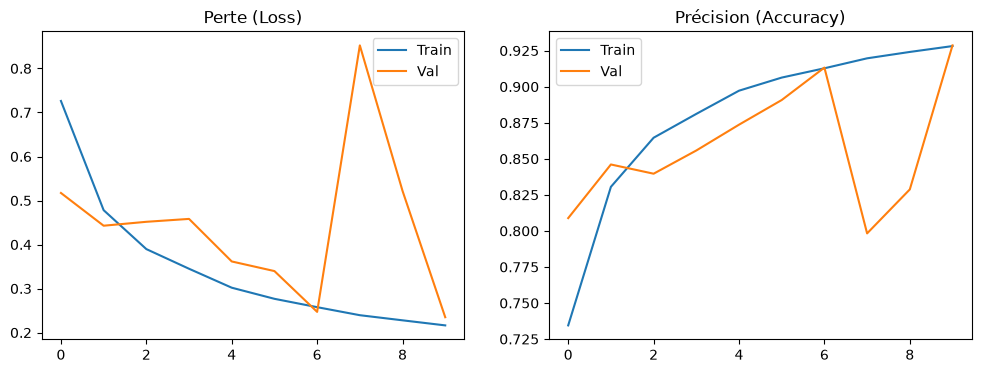

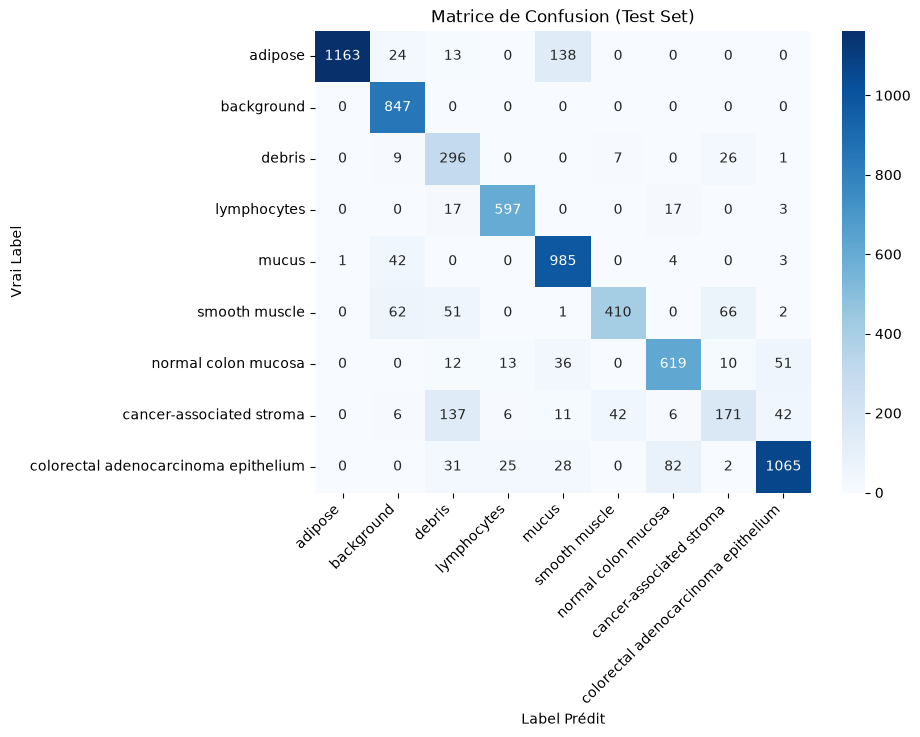


Rapport de classification :
                                      precision    recall  f1-score   support

                             adipose       1.00      0.87      0.93      1338
                          background       0.86      1.00      0.92       847
                              debris       0.53      0.87      0.66       339
                         lymphocytes       0.93      0.94      0.94       634
                               mucus       0.82      0.95      0.88      1035
                       smooth muscle       0.89      0.69      0.78       592
                 normal colon mucosa       0.85      0.84      0.84       741
            cancer-associated stroma       0.62      0.41      0.49       421
colorectal adenocarcinoma epithelium       0.91      0.86      0.89      1233

                            accuracy                           0.86      7180
                           macro avg       0.82      0.83      0.81      7180
                        weighted 

In [14]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

# Choix du matériel (GPU si disponible)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Utilisation du matériel : {device}")


# ==========================================
# ÉTAPE 2 : DONNÉES ET DATA AUGMENTATION
# ==========================================
# Transformations avec Data Augmentation pour l'entraînement
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# Transformations standards pour la validation et le test (pas d'aléa)
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# Chargement des datasets
train_dataset = PathMNIST(split='train', transform=train_transform, download=True)
val_dataset   = PathMNIST(split='val', transform=eval_transform, download=True)
test_dataset  = PathMNIST(split='test', transform=eval_transform, download=True)

# DataLoaders
BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

labels_map = train_dataset.info['label']
num_classes = len(labels_map)
print(f"Nombre de classes : {num_classes}")


# ==========================================
# ÉTAPE 3 : ARCHITECTURE DU MODÈLE (CNN)
# ==========================================
class PathMNISTNet(nn.Module):
    def __init__(self, num_classes=9):
        super(PathMNISTNet, self).__init__()
        
        self.features = nn.Sequential(
            # Bloc 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 14x14
            
            # Bloc 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 7x7
            
            # Bloc 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU()
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.5), # Dropout de 0.5 pour régulariser
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = PathMNISTNet(num_classes=num_classes).to(device)


# ==========================================
# ÉTAPE 4 : ENTRAÎNEMENT, VALIDATION ET SCHEDULER
# ==========================================
criterion = nn.CrossEntropyLoss()
# Ajout du weight_decay=1e-4 pour la régularisation L2
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

# Scheduler pour baisser automatiquement le Learning Rate si la perte de validation stagne
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, targets in loader:
        inputs = inputs.to(device)
        targets = targets.squeeze().long().to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()
        
    return running_loss / total, correct / total

def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)
            targets = targets.squeeze().long().to(device)
            
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            
            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()
            
    return running_loss / total, correct / total

EPOCHS = 10
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

print("Début de l'entraînement...")
for epoch in range(EPOCHS):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)
    
    # Mise à jour du Learning Rate en fonction de la perte de validation
    scheduler.step(val_loss)
    
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    
    print(f"Époque [{epoch+1}/{EPOCHS}] | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc*100:.2f}%")


# ==========================================
# ÉTAPE 5 : ÉVALUATION ET VISUALISATION
# ==========================================
# 1. Courbes d'apprentissage
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history['train_loss'], label='Train')
ax1.plot(history['val_loss'], label='Val')
ax1.set_title('Perte (Loss)')
ax1.legend()

ax2.plot(history['train_acc'], label='Train')
ax2.plot(history['val_acc'], label='Val')
ax2.set_title('Précision (Accuracy)')
ax2.legend()
plt.show()

# 2. Évaluation sur le test set
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_targets.extend(targets.squeeze().numpy())

# Matrice de confusion
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_map.values(),
            yticklabels=labels_map.values())
plt.ylabel('Vrai Label')
plt.xlabel('Label Prédit')
plt.title('Matrice de Confusion (Test Set)')
plt.xticks(rotation=45, ha='right')
plt.show()

# Rapport de classification
print("\nRapport de classification :")
print(classification_report(all_targets, all_preds, target_names=list(labels_map.values())))

- L'accuracy finale a atteint 92.86% sur l'ensemble de validation à la 10e époque. Le modèle a franchi un palier.
- La val présente toujours le pic brusque, et l'accuracy chuteà 79.83%.
- Lorsque le modèle a commencé à stagner ou à s'approcher d'un minimum local, le scheduler a divisé brutalement le learning rate par 2.
- Les époques 9 et 10 ont changé et se sont stabilisées, ce qui a rendu le scheduler plus efficace. 
